<a href="https://colab.research.google.com/github/kavyaayyappan1998/DATA266---2738/blob/main/Assignment10/Homework_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q datasets chromadb sentence-transformers pandas

In [2]:
import re, textwrap, statistics
from collections import defaultdict

import numpy as np
import pandas as pd
import chromadb
from datasets import load_dataset
from sentence_transformers import SentenceTransformer, CrossEncoder

# ----------------------------- configuration -----------------------------
N_DOCS          = 100     # first 100 training documents
CHUNK_WORDS     = 200     # target chunk size (words) for both strategies
CHUNK_OVERLAP   = 40      # word overlap for strategy 1
SENT_OVERLAP    = 1       # sentence overlap for strategy 2
EMBED_MODEL     = "sentence-transformers/all-MiniLM-L6-v2"
RERANK_MODEL    = "cross-encoder/ms-marco-MiniLM-L-6-v2"
FETCH_K         = 20      # candidates fetched from the vector DB (and passed to the reranker)
TOP_K           = 5       # K used for Precision@K / Recall@K
N_EVAL_QUERIES  = 10      # number of evaluation queries (>= 2 required)

pd.set_option("display.max_colwidth", 120)

1. Load the dataset


In [3]:
def load_first_n(n=N_DOCS):
    attempts = [
        dict(),                                   # normal repo
        dict(revision="refs/convert/parquet"),    # auto-converted parquet branch (fallback)
    ]
    last_err = None
    for kw in attempts:
        try:
            ds = load_dataset("ccdv/arxiv-summarization", "document",
                              split="train", streaming=True, **kw)
            return list(ds.take(n))
        except Exception as e:
            last_err = e
            print("load attempt failed:", type(e).__name__, str(e)[:150])
    raise last_err

raw_docs = load_first_n()
print("documents loaded:", len(raw_docs))
print("fields:", list(raw_docs[0].keys()))
print("article preview :", raw_docs[0]["article"][:300], "...")
print("abstract preview:", raw_docs[0]["abstract"][:300], "...")

documents loaded: 100
fields: ['article', 'abstract']
article preview : additive models @xcite provide an important family of models for semiparametric regression or classification . some reasons for the success of additive models are their increased flexibility when compared to linear or generalized linear models and their increased interpretability when compared to fu ...
abstract preview: additive models play an important role in semiparametric statistics . 
 this paper gives learning rates for regularized kernel based methods for additive models . 
 these learning rates compare favourably in particular in high dimensions to recent results on optimal learning rates for purely nonpara ...


 2. Preprocessing

In [4]:
def clean_text(text: str) -> str:
    text = text.replace("\n", " ")
    text = re.sub(r"@x\w+", " ", text)                 # @xmath12, @xcite, @xref ...
    text = re.sub(r"\(\s*[,;]*\s*\)|\[\s*[,;]*\s*\]", " ", text)   # emptied brackets
    text = re.sub(r"\s+([.,;:!?])", r"\1", text)       # "word ." -> "word."
    text = re.sub(r"\s+", " ", text)
    return text.strip()

docs = []
for i, d in enumerate(raw_docs):
    article  = clean_text(d["article"])
    abstract = clean_text(d["abstract"])
    if len(article.split()) < 50:        # skip empty / broken records
        continue
    docs.append({"doc_id": i, "article": article, "abstract": abstract})

lengths = [len(d["article"].split()) for d in docs]
print(f"usable documents: {len(docs)}")
print(f"article length (words): min={min(lengths)}, median={int(statistics.median(lengths))}, max={max(lengths)}")

usable documents: 100
article length (words): min=474, median=4090, max=27420


 3. Two chunking strategies

**Strategy 1, fixed:** 200-word sliding windows with 40 words of overlap. Uniform size, but boundaries fall mid-sentence.

**Strategy 2, sentence-aware:** whole sentences packed into chunks of up to 200 words, with one sentence of overlap. Variable size, but no sentence is cut.

In [5]:
def chunk_fixed(text, size=CHUNK_WORDS, overlap=CHUNK_OVERLAP):
    words = text.split()
    step = size - overlap
    chunks = []
    for start in range(0, len(words), step):
        chunks.append(" ".join(words[start:start + size]))
        if start + size >= len(words):
            break
    return chunks

_SENT_SPLIT = re.compile(r"(?<=[.!?])\s+")

def split_sentences(text):
    return [s.strip() for s in _SENT_SPLIT.split(text) if s.strip()]

def chunk_sentences(text, max_words=CHUNK_WORDS, overlap_sents=SENT_OVERLAP):
    # break up any single "sentence" that is longer than the budget
    sents = []
    for s in split_sentences(text):
        w = s.split()
        if len(w) <= max_words:
            sents.append(s)
        else:
            sents.extend(" ".join(w[i:i + max_words]) for i in range(0, len(w), max_words))

    chunks, current, n_words = [], [], 0
    for s in sents:
        n = len(s.split())
        if current and n_words + n > max_words:
            chunks.append(" ".join(current))
            current = current[-overlap_sents:] if overlap_sents else []
            n_words = sum(len(x.split()) for x in current)
            if n_words + n > max_words:          # overlap would overflow -> drop it
                current, n_words = [], 0
        current.append(s)
        n_words += n
    if current:
        chunks.append(" ".join(current))
    return chunks

STRATEGIES = {"fixed": chunk_fixed, "sentence": chunk_sentences}

chunks = {}      # strategy -> list of {"id", "doc_id", "chunk_idx", "text"}
for name, fn in STRATEGIES.items():
    rows = []
    for d in docs:
        for j, c in enumerate(fn(d["article"])):
            rows.append({"id": f"{name}-d{d['doc_id']}-c{j}", "doc_id": d["doc_id"], "chunk_idx": j, "text": c})
    chunks[name] = rows

stats = []
for name, rows in chunks.items():
    wl = [len(r["text"].split()) for r in rows]
    stats.append({"strategy": name, "n_chunks": len(rows), "mean_words": round(np.mean(wl), 1),
                  "min_words": min(wl), "max_words": max(wl), "std_words": round(np.std(wl), 1)})
display(pd.DataFrame(stats))

for name in STRATEGIES:
    print(f"\n[{name}] example chunk:\n", textwrap.fill(chunks[name][1]["text"][:500], 110), "...")

,strategy,n_chunks,mean_words,min_words,max_words,std_words
0,fixed,3468,197.9,46,200,14.7
1,sentence,3419,182.3,18,200,23.5



[fixed] example chunk:
 and therefore regularized kernel based methods based on this loss function typically suffer on bad statistical
robustness properties, even if the kernel is bounded. this is in sharp contrast to kernel methods based on a
lipschitz continuous loss function and on a bounded loss function, where results on upper bounds for the
maxbias bias and on a bounded influence function are known, see e.g. for the general case and for additive
models. therefore, we will here consider the case of regularized ker ...

[sentence] example chunk:
 of course, the least squares loss function is differentiable and has many nice mathematical properties, but it
is only locally lipschitz continuous and therefore regularized kernel based methods based on this loss
function typically suffer on bad statistical robustness properties, even if the kernel is bounded. this is in
sharp contrast to kernel methods based on a lipschitz continuous loss function and on a bounded loss function,
where r

4. Embed and index in ChromaDB

In [6]:
embedder = SentenceTransformer(EMBED_MODEL)
client = chromadb.Client()          # in-memory; use chromadb.PersistentClient(path="chroma_db") to persist

collections = {}
for name, rows in chunks.items():
    cname = f"arxiv_{name}"
    try:
        client.delete_collection(cname)      # makes the cell safe to re-run
    except Exception:
        pass
    col = client.create_collection(cname, metadata={"hnsw:space": "cosine"})

    texts = [r["text"] for r in rows]
    embs = embedder.encode(texts, batch_size=64, normalize_embeddings=True, show_progress_bar=True)

    B = 1000                                  # stay under Chroma's max batch size
    for s in range(0, len(rows), B):
        part = rows[s:s + B]
        col.add(ids=[r["id"] for r in part],
                documents=[r["text"] for r in part],
                metadatas=[{"doc_id": r["doc_id"], "chunk_idx": r["chunk_idx"]} for r in part],
                embeddings=embs[s:s + B].tolist())
    collections[name] = col
    print(f"{cname}: {col.count()} vectors indexed")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/55 [00:00<?, ?it/s]

arxiv_fixed: 3468 vectors indexed


Batches:   0%|          | 0/54 [00:00<?, ?it/s]

arxiv_sentence: 3419 vectors indexed


5. Queries and relevance definition


**Queries.** Ten hand-written natural-language questions, one per paper (papers 0–9), phrased as a user would ask them rather than copied from the text.

**Relevance (manual).** For each question, the top-10 chunks from dense retrieval and from reranking were pooled (212 chunks in total) and each was judged by hand: 1 if the chunk helps answer the question, 0 if not. Introductions, method setup, equations and reference lists were marked 0 even when they come from the right paper. Chunks from other papers count as not relevant.

**Recall@K** = relevant chunks in the top K ÷ all chunks judged relevant for that question.

The follow-up (memory) experiment uses paper-level relevance: a chunk is relevant if it comes from the paper under discussion.

In [7]:
CUSTOM_QUERIES = {
    0: "How fast can support vector machines learn when the regression function has an additive structure?",
    1: "What branching fraction was measured for the leptonic decay of a charm meson to a tau and a neutrino at CLEO-c?",
    2: "Is current reversal in a deterministic ratchet linked to a transition from chaotic to periodic motion?",
    3: "Can a phase diffuser reduce the scintillation of a laser beam?",
    4: "What do generalized form factors reveal about how quarks contribute to the spin of the nucleon?",
    5: "For which values of p do the dilated p-sine functions form a basis?",
    6: "Why is second harmonic generation enhanced in silicon carbide nanopillars in the mid-infrared?",
    7: "How does synaptic memory support learning and cognition?",
    8: "How can prior shape models and b-scale be used to recognize objects automatically in medical images?",
    9: "Have additional planets been found in known planetary systems using long-term radial velocity measurements?",
}

def query_from_abstract(abstract, min_words=12, max_words=35):
    out = []
    for s in split_sentences(abstract):
        out.extend(s.split())
        if len(out) >= min_words:
            break
    return " ".join(out[:max_words]).rstrip(".")

eval_queries = []      # list of {"qid", "doc_id", "query"}
for d in docs:
    if len(eval_queries) >= N_EVAL_QUERIES:
        break
    q = CUSTOM_QUERIES.get(d["doc_id"]) or query_from_abstract(d["abstract"])
    if len(q.split()) < 8:
        continue
    eval_queries.append({"qid": f"q{len(eval_queries) + 1}", "doc_id": d["doc_id"], "query": q})

for doc_id, q in CUSTOM_QUERIES.items():          # custom queries beyond the first N docs
    if not any(e["doc_id"] == doc_id for e in eval_queries):
        eval_queries.append({"qid": f"q{len(eval_queries) + 1}", "doc_id": doc_id, "query": q})

display(pd.DataFrame(eval_queries))

,qid,doc_id,query
0,q1,0,How fast can support vector machines learn when the regression function has an additive structure?
1,q2,1,What branching fraction was measured for the leptonic decay of a charm meson to a tau and a neutrino at CLEO-c?
2,q3,2,Is current reversal in a deterministic ratchet linked to a transition from chaotic to periodic motion?
3,q4,3,Can a phase diffuser reduce the scintillation of a laser beam?
4,q5,4,What do generalized form factors reveal about how quarks contribute to the spin of the nucleon?
5,q6,5,For which values of p do the dilated p-sine functions form a basis?
6,q7,6,Why is second harmonic generation enhanced in silicon carbide nanopillars in the mid-infrared?
7,q8,7,How does synaptic memory support learning and cognition?
8,q9,8,How can prior shape models and b-scale be used to recognize objects automatically in medical images?
9,q10,9,Have additional planets been found in known planetary systems using long-term radial velocity measurements?


6. Retrieval **without** reranking (dense only)

In [8]:
def dense_search(strategy, query, n=FETCH_K):
    q_emb = embedder.encode([query], normalize_embeddings=True).tolist()
    res = collections[strategy].query(query_embeddings=q_emb, n_results=n,
                                      include=["documents", "metadatas", "distances"])
    return [{"id": i, "text": t, "doc_id": m["doc_id"], "chunk_idx": m["chunk_idx"], "score": 1 - dist}
            for i, t, m, dist in zip(res["ids"][0], res["documents"][0], res["metadatas"][0], res["distances"][0])]

def show(results, target_doc, k=TOP_K, score_name="score"):
    rows = [{"rank": r + 1, "rel": "✓" if c["doc_id"] == target_doc else "✗", "doc_id": c["doc_id"],
             "chunk": c["chunk_idx"], score_name: round(float(c["score"]), 4), "text": c["text"][:110] + "..."}
            for r, c in enumerate(results[:k])]
    display(pd.DataFrame(rows))

SAMPLE = eval_queries[:2]
for q in SAMPLE:
    print("=" * 110)
    print(f"{q['qid']} (target paper doc_id={q['doc_id']}): {q['query']}")
    for strategy in STRATEGIES:
        print(f"\n-- dense retrieval, chunking = {strategy}")
        show(dense_search(strategy, q["query"]), q["doc_id"], score_name="cosine")

q1 (target paper doc_id=0): How fast can support vector machines learn when the regression function has an additive structure?

-- dense retrieval, chunking = fixed


,rank,rel,doc_id,chunk,cosine,text
0,1,✓,0,7,0.6303,of the paper has the following structure. section [ ratessection ] contains our main results on learning rates...
1,2,✓,0,16,0.6055,theoretical and numerical comparisons on the goodness of our learning rates with those from the literature. as...
2,3,✓,0,2,0.5853,"we address the open question, whether an svm with an additive kernel can provide a substantially better learni..."
3,4,✓,0,0,0.5543,additive models provide an important family of models for semiparametric regression or classification. some re...
4,5,✓,0,18,0.4986,may be improved by relaxing assumption 1 to a sobolev smoothness condition for and a regularity condition for ...



-- dense retrieval, chunking = sentence


,rank,rel,doc_id,chunk,cosine,text
0,1,✓,0,17,0.6266,"as already mentioned in the introduction, some reasons for the popularity of additive models are flexibility, ..."
1,2,✓,0,7,0.6004,denote the marginal distribution of on as. under the assumption that for each and that is dense in in the -met...
2,3,✓,0,3,0.5854,for the same reason we will also not cover sparsity. consistency of support vector machines generated by addit...
3,4,✓,0,0,0.5623,additive models provide an important family of models for semiparametric regression or classification. some re...
4,5,✓,0,2,0.5597,"such regularized kernel based methods are now often called support vector machines ( svms ), although the nota..."


q2 (target paper doc_id=1): What branching fraction was measured for the leptonic decay of a charm meson to a tau and a neutrino at CLEO-c?

-- dense retrieval, chunking = fixed


,rank,rel,doc_id,chunk,cosine,text
0,1,✓,1,2,0.7250,"sector. among the leptonic decays in the charm - quark sector, decays are more accessible since they are ckm f..."
1,2,✗,11,5,0.6989,this paper unless specifically indicated. ) the absolute branching fractions for charm mesons have been measur...
2,3,✓,1,12,0.6875,- sign signal electron in events with. the uncertainty in the measurement from this source is estimated to be....
3,4,✓,1,13,0.6835,branching fractions only and is the most precise determination of the leptonic decay constant to date. our com...
4,5,✗,11,4,0.6586,"also doubly reconstructed, where all combinations of modes may be used. i denote the number of observed single..."



-- dense retrieval, chunking = sentence


,rank,rel,doc_id,chunk,cosine,text
0,1,✓,1,2,0.7546,"furthermore, the large mass of the lepton removes the helicity suppression that is present in the decays to li..."
1,2,✗,11,5,0.7019,) the absolute branching fractions for charm mesons have been measured with unprecedented accuracy. combining ...
2,3,✓,1,12,0.6897,"other possible sources of systematic uncertainty include, tag bias, tracking efficiency, identification effici..."
3,4,✗,11,4,0.6455,"i denote the number of observed single tag charmed particles as, anti - charmed particles as, and double tags ..."
4,5,✓,1,6,0.5978,"our double - tag ( dt ) sample is formed from events with only a single charged track, identified as an, in ad..."


7. Retrieval **with** reranking


In [9]:
reranker = CrossEncoder(RERANK_MODEL)

def rerank(query, candidates):
    scores = reranker.predict([(query, c["text"]) for c in candidates])
    out = [dict(c, score=float(s)) for c, s in zip(candidates, scores)]
    return sorted(out, key=lambda c: c["score"], reverse=True)

def retrieve(strategy, query, use_rerank=False, n=FETCH_K):
    cands = dense_search(strategy, query, n)
    return rerank(query, cands) if use_rerank else cands

for q in SAMPLE:
    print("=" * 110)
    print(f"{q['qid']} (target paper doc_id={q['doc_id']}): {q['query']}")
    for strategy in STRATEGIES:
        print(f"\n-- dense + cross-encoder rerank, chunking = {strategy}")
        show(retrieve(strategy, q["query"], use_rerank=True), q["doc_id"], score_name="ce_score")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

q1 (target paper doc_id=0): How fast can support vector machines learn when the regression function has an additive structure?

-- dense + cross-encoder rerank, chunking = fixed


,rank,rel,doc_id,chunk,ce_score,text
0,1,✓,0,7,2.0935,of the paper has the following structure. section [ ratessection ] contains our main results on learning rates...
1,2,✓,0,2,1.2884,"we address the open question, whether an svm with an additive kernel can provide a substantially better learni..."
2,3,✓,0,1,-2.4859,and therefore regularized kernel based methods based on this loss function typically suffer on bad statistical...
3,4,✓,0,21,-2.9963,"we use the same sequence of regularizing parameters as in ( *??? 4.9, cor. 4.12 ), i.e., where,, $ ], and is s..."
4,5,✓,0,0,-3.5847,additive models provide an important family of models for semiparametric regression or classification. some re...



-- dense + cross-encoder rerank, chunking = sentence


,rank,rel,doc_id,chunk,ce_score,text
0,1,✓,0,2,2.6483,"such regularized kernel based methods are now often called support vector machines ( svms ), although the nota..."
1,2,✓,0,3,1.0292,for the same reason we will also not cover sparsity. consistency of support vector machines generated by addit...
2,3,✓,0,7,0.9559,denote the marginal distribution of on as. under the assumption that for each and that is dense in in the -met...
3,4,✓,0,20,-2.4520,let us now add some numerical comparisons on the goodness of our learning rates given by theorem [ mainratesth...
4,5,✓,0,0,-3.5336,additive models provide an important family of models for semiparametric regression or classification. some re...


q2 (target paper doc_id=1): What branching fraction was measured for the leptonic decay of a charm meson to a tau and a neutrino at CLEO-c?

-- dense + cross-encoder rerank, chunking = fixed


,rank,rel,doc_id,chunk,ce_score,text
0,1,✗,11,5,5.7391,this paper unless specifically indicated. ) the absolute branching fractions for charm mesons have been measur...
1,2,✓,1,2,4.4621,"sector. among the leptonic decays in the charm - quark sector, decays are more accessible since they are ckm f..."
2,3,✓,1,3,2.9148,an improved measurement of the absolute branching fraction of the leptonic decay ( charge - conjugate modes ar...
3,4,✓,1,12,1.7292,- sign signal electron in events with. the uncertainty in the measurement from this source is estimated to be....
4,5,✗,11,1,0.8973,"great deal about strong interactions, especially decay constants and final state interactions. charm has been ..."



-- dense + cross-encoder rerank, chunking = sentence


,rank,rel,doc_id,chunk,ce_score,text
0,1,✗,11,5,5.9414,) the absolute branching fractions for charm mesons have been measured with unprecedented accuracy. combining ...
1,2,✓,1,2,3.3831,"furthermore, the large mass of the lepton removes the helicity suppression that is present in the decays to li..."
2,3,✓,1,3,3.0232,"in this article, we report an improved measurement of the absolute branching fraction of the leptonic decay ( ..."
3,4,✓,1,12,2.4604,"other possible sources of systematic uncertainty include, tag bias, tracking efficiency, identification effici..."
4,5,✓,1,6,1.2937,"our double - tag ( dt ) sample is formed from events with only a single charged track, identified as an, in ad..."


8. Conversational memory

A buffer keeps the previous user turns. For a new question, the last 2 turns are prepended to it to form a standalone search query, which is used for both dense search and reranking. The demo runs the same two-turn conversation without and with memory; turn 2 ("that work") depends on turn 1.

In [10]:
class ConversationMemory:
    # Buffer-window memory: keeps past turns and rewrites follow-ups into standalone queries.
    def __init__(self, window=2):
        self.window = window
        self.turns = []                       # [{"query", "search_query", "chunk_ids"}]

    def contextualize(self, query):
        history = [t["query"] for t in self.turns[-self.window:]]
        return " ".join(history + [query]) if history else query

    def add(self, query, search_query, results):
        self.turns.append({"query": query, "search_query": search_query,
                           "chunk_ids": [r["id"] for r in results[:TOP_K]]})

    def clear(self):
        self.turns = []


def chat_turn(strategy, query, memory=None, use_rerank=True):
    # One conversational retrieval turn. memory=None -> stateless (no memory).
    search_query = memory.contextualize(query) if memory is not None else query
    results = retrieve(strategy, search_query, use_rerank=use_rerank)
    if memory is not None:
        memory.add(query, search_query, results)
    return search_query, results


FOLLOW_UPS = [
    "What are the main results and conclusions of that work?",
    "What method or approach do they use to address this?",
]

# ---- multi-turn demo -------------------------------------------------------------
demo = eval_queries[0]
turn1, turn2 = demo["query"], FOLLOW_UPS[0]
DEMO_STRATEGY = "sentence"

print("TURN 1:", turn1)
print("TURN 2:", turn2, "   <-- depends on turn 1\n")

print("################ WITHOUT memory ################")
_, r1 = chat_turn(DEMO_STRATEGY, turn1, memory=None)
sq, r2 = chat_turn(DEMO_STRATEGY, turn2, memory=None)
print("search query used for turn 2:", sq)
show(r2, demo["doc_id"], score_name="ce_score")

print("################ WITH memory ################")
mem = ConversationMemory(window=2)
_, r1 = chat_turn(DEMO_STRATEGY, turn1, memory=mem)
sq, r2 = chat_turn(DEMO_STRATEGY, turn2, memory=mem)
print("search query used for turn 2:", textwrap.shorten(sq, 220))
show(r2, demo["doc_id"], score_name="ce_score")
print("memory now holds", len(mem.turns), "turns")

TURN 1: How fast can support vector machines learn when the regression function has an additive structure?
TURN 2: What are the main results and conclusions of that work?    <-- depends on turn 1

################ WITHOUT memory ################
search query used for turn 2: What are the main results and conclusions of that work?


,rank,rel,doc_id,chunk,ce_score,text
0,1,✗,5,14,-5.7782,the conclusion follows by defining either or. we now examine other further consequences of the corollaries [ m...
1,2,✗,90,40,-6.4477,"[ results ]. in addition to the analysis of sec. [ results ], two other analyses have been made by modifying e..."
2,3,✗,23,28,-7.1702,"for brighter sources, our upper limits on density are similar to those obtained in legacy fields, and strength..."
3,4,✗,65,4,-7.3059,"after considering the implications of on the ut, let s explore now. since is an odd function of, it is therefo..."
4,5,✗,90,44,-7.8033,"however, as indicated in the reductions in the analyses 2 and 3, it is clear that their curves are closer to t..."


################ WITH memory ################
search query used for turn 2: How fast can support vector machines learn when the regression function has an additive structure? What are the main results and conclusions of that work?


,rank,rel,doc_id,chunk,ce_score,text
0,1,✓,0,2,1.9572,"such regularized kernel based methods are now often called support vector machines ( svms ), although the nota..."
1,2,✓,0,7,1.6309,denote the marginal distribution of on as. under the assumption that for each and that is dense in in the -met...
2,3,✓,0,3,0.7780,for the same reason we will also not cover sparsity. consistency of support vector machines generated by addit...
3,4,✓,0,0,-3.0101,additive models provide an important family of models for semiparametric regression or classification. some re...
4,5,✓,0,22,-3.5676,all of these values of are positive with the exceptions if or. this is in contrast to the corresponding expone...


memory now holds 2 turns


In [11]:
# Export the candidate chunks that need a manual relevance judgement
POOL_DEPTH = 10      # judge the top-10 of each system (dense and reranked)

rows = []
for strategy in STRATEGIES:
    for q in eval_queries:
        dense = dense_search(strategy, q["query"])
        reranked = rerank(q["query"], dense)
        pool = {c["id"]: c for c in dense[:POOL_DEPTH] + reranked[:POOL_DEPTH]}
        for c in pool.values():
            if c["doc_id"] == q["doc_id"]:          # chunks from other papers are counted as not relevant
                rows.append({"qid": q["qid"], "query": q["query"], "strategy": strategy,
                             "chunk_id": c["id"], "relevant": "", "text": c["text"]})

pool_df = pd.DataFrame(rows)
pool_df.to_csv("relevance_pool.csv", index=False)
print(len(pool_df), "chunks to judge -> relevance_pool.csv")

try:
    from google.colab import files
    files.download("relevance_pool.csv")
except Exception:
    pass

212 chunks to judge -> relevance_pool.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
# Load manual chunk-level labels (1 = useful for answering the query, 0 = not)
import os
from google.colab import drive
drive.mount("/content/drive")

candidates = ["/content/drive/MyDrive/DATA266/relevance_labels.csv",   # Google Drive
              "relevance_labels.csv"]                                  # Colab working folder
LABELS_PATH = next((p for p in candidates if os.path.exists(p)), None)

LABELS = None
if LABELS_PATH:
    lab = pd.read_csv(LABELS_PATH).dropna(subset=["relevant"])
    LABELS = {(r.qid, r.chunk_id): int(r.relevant) for r in lab.itertuples()}
    missing = [(r.qid, r.chunk_id) for r in pool_df.itertuples() if (r.qid, r.chunk_id) not in LABELS]
    print(f"loaded {len(LABELS)} labels from {LABELS_PATH}, {sum(LABELS.values())} relevant, {len(missing)} pool chunks unlabelled")
else:
    print("relevance_labels.csv not found -> falling back to paper-level relevance")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
loaded 212 labels from /content/drive/MyDrive/DATA266/relevance_labels.csv, 107 relevant, 0 pool chunks unlabelled


9. Evaluation — Precision@K, Recall@K, MRR

* **Precision@5** = relevant chunks in the top 5 ÷ 5
* **Recall@5** = relevant chunks in the top 5 ÷ all relevant chunks for the question
* **MRR** = mean of 1 ÷ rank of the first relevant chunk (0 if none in the top 20)

In [31]:
def precision_at_k(ranked_ids, relevant, k):
    return sum(1 for i in ranked_ids[:k] if i in relevant) / k

def recall_at_k(ranked_ids, relevant, k):
    return sum(1 for i in ranked_ids[:k] if i in relevant) / len(relevant) if relevant else 0.0

def reciprocal_rank(ranked_ids, relevant):
    for r, i in enumerate(ranked_ids, start=1):
        if i in relevant:
            return 1.0 / r
    return 0.0

def score_systems(runs, target_doc, qid=None, labels=None, k=TOP_K):
    # labels given  -> relevant = chunks manually marked 1 for this query
    # labels absent -> relevant = pooled chunks from the target paper
    pooled = {c["id"]: c for res in runs.values() for c in res}
    if labels is not None:
        relevant = {i for i in pooled if labels.get((qid, i), 0) == 1}
    else:
        relevant = {i for i, c in pooled.items() if c["doc_id"] == target_doc}
    out = {}
    for name, res in runs.items():
        ids = [c["id"] for c in res]
        out[name] = {f"P@{k}": precision_at_k(ids, relevant, k),
                     f"R@{k}": recall_at_k(ids, relevant, k),
                     "MRR": reciprocal_rank(ids, relevant)}
    return out

records = []

for strategy in STRATEGIES:
    for n, q in enumerate(eval_queries):
        # ---- Experiment A: single-turn, without vs with reranking (manual chunk-level labels)
        dense = dense_search(strategy, q["query"])
        runs = {"no rerank": dense, "rerank": rerank(q["query"], dense)}
        for system, m in score_systems(runs, q["doc_id"], qid=q["qid"], labels=LABELS).items():
            records.append({"experiment": "single-turn", "strategy": strategy, "system": system, "qid": q["qid"], **m})

        # ---- Experiment B: follow-up turn, without vs with memory (paper-level relevance)
        follow_up = FOLLOW_UPS[n % len(FOLLOW_UPS)]
        _, no_mem = chat_turn(strategy, follow_up, memory=None)
        mem = ConversationMemory(window=2)
        chat_turn(strategy, q["query"], memory=mem)
        _, with_mem = chat_turn(strategy, follow_up, memory=mem)
        runs = {"no memory": no_mem, "memory": with_mem}
        for system, m in score_systems(runs, q["doc_id"]).items():
            records.append({"experiment": "follow-up", "strategy": strategy, "system": system, "qid": q["qid"], **m})

results_df = pd.DataFrame(records)
METRICS = [f"P@{TOP_K}", f"R@{TOP_K}", "MRR"]
print("evaluated", len(eval_queries), "queries x", len(STRATEGIES), "chunking strategies |",
      "relevance:", "manual chunk-level" if LABELS else "paper-level")
results_df.head()

evaluated 10 queries x 2 chunking strategies | relevance: manual chunk-level


,experiment,strategy,system,qid,P@5,R@5,MRR
0,single-turn,fixed,no rerank,q1,0.4,0.400000,1.000000
1,single-turn,fixed,rerank,q1,0.4,0.400000,1.000000
2,follow-up,fixed,no memory,q1,0.0,0.000000,0.000000
3,follow-up,fixed,memory,q1,1.0,0.294118,1.000000
4,single-turn,fixed,no rerank,q2,0.4,0.500000,0.333333


9.1 Without vs with reranking

In [32]:
single = results_df[results_df.experiment == "single-turn"]
t_rerank = single.groupby(["strategy", "system"])[METRICS].mean().round(3)
display(t_rerank)
print("Averaged over both chunking strategies:")
display(single.groupby("system")[METRICS].mean().round(3))

P@5    R@5    MRR
strategy system                       
fixed    no rerank  0.56  0.439  0.727
         rerank     0.58  0.461  0.722
sentence no rerank  0.52  0.504  0.794
         rerank     0.56  0.512  0.672

Averaged over both chunking strategies:


,P@5,R@5,MRR
system,,,
no rerank,0.54,0.472,0.761
rerank,0.57,0.487,0.697


### 9.2 Chunking strategy 1 (fixed) vs strategy 2 (sentence-aware)

In [33]:
t_chunk = single.groupby(["system", "strategy"])[METRICS].mean().round(3)
display(t_chunk)
print("Averaged over both retrieval modes:")
display(single.groupby("strategy")[METRICS].mean().round(3))

P@5    R@5    MRR
system    strategy                    
no rerank fixed     0.56  0.439  0.727
          sentence  0.52  0.504  0.794
rerank    fixed     0.58  0.461  0.722
          sentence  0.56  0.512  0.672

Averaged over both retrieval modes:


,P@5,R@5,MRR
strategy,,,
fixed,0.57,0.450,0.724
sentence,0.54,0.508,0.733


 9.3 Without vs with conversational memory (follow-up turn)

In [34]:
follow = results_df[results_df.experiment == "follow-up"]
t_mem = follow.groupby(["strategy", "system"])[METRICS].mean().round(3)
display(t_mem)
print("Averaged over both chunking strategies:")
display(follow.groupby("system")[METRICS].mean().round(3))

P@5    R@5    MRR
strategy system                       
fixed    memory     0.98  0.354  0.950
         no memory  0.00  0.000  0.007
sentence memory     0.96  0.377  0.950
         no memory  0.00  0.000  0.000

Averaged over both chunking strategies:


,P@5,R@5,MRR
system,,,
memory,0.97,0.366,0.950
no memory,0.00,0.000,0.004


9.4 Summary table and chart

,experiment,strategy,system,P@5,R@5,MRR
5,single-turn,fixed,rerank,0.58,0.461,0.722
4,single-turn,fixed,no rerank,0.56,0.439,0.727
7,single-turn,sentence,rerank,0.56,0.512,0.672
6,single-turn,sentence,no rerank,0.52,0.504,0.794
1,follow-up,fixed,no memory,0.00,0.000,0.007
0,follow-up,fixed,memory,0.98,0.354,0.950
3,follow-up,sentence,no memory,0.00,0.000,0.000
2,follow-up,sentence,memory,0.96,0.377,0.950


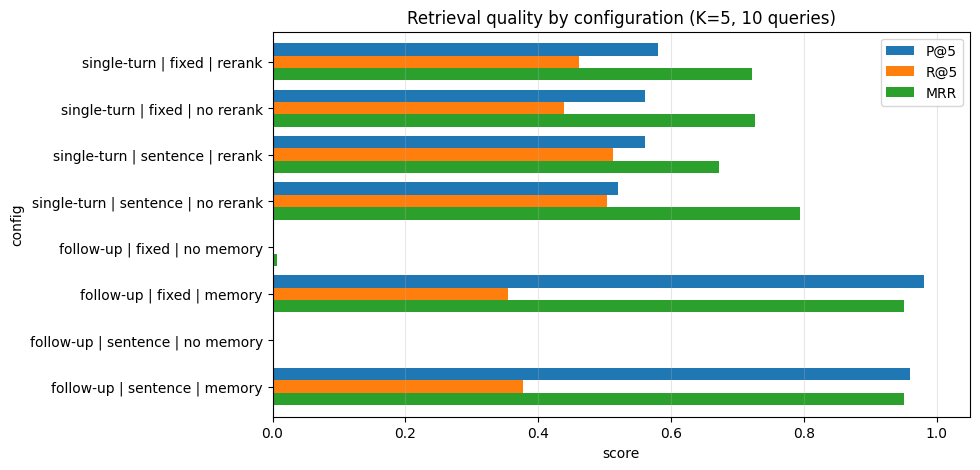

In [35]:
summary = (results_df.groupby(["experiment", "strategy", "system"])[METRICS].mean().round(3)
           .reset_index().sort_values(["experiment", "strategy", "system"], ascending=[False, True, False]))
display(summary)

ax = (summary.assign(config=summary.experiment + " | " + summary.strategy + " | " + summary.system)
      .set_index("config")[METRICS].plot.barh(figsize=(9, 5), width=0.8))
ax.set_xlabel("score"); ax.set_xlim(0, 1.05); ax.invert_yaxis()
ax.set_title(f"Retrieval quality by configuration (K={TOP_K}, {len(eval_queries)} queries)")
ax.grid(axis="x", alpha=0.3)

 Findings (K=5, 10 queries, averaged over the other factor)
1. Without vs with reranking: P@5 0.540 → 0.570 (+0.030), R@5 0.472 → 0.487 (+0.015), MRR 0.761 → 0.697 (-0.063)
Reranking gave a mixed result: some metrics rose and others fell, so it changes which relevant chunks reach the top 5 without a clear overall gain.
2. Chunking, fixed vs sentence-aware: P@5 0.570 → 0.540 (-0.030), R@5 0.450 → 0.508 (+0.058), MRR 0.724 → 0.733 (+0.009)
The chunking comparison is mixed: neither strategy wins on all metrics.
3. Follow-up turn, without vs with memory: P@5 0.000 → 0.970 (+0.970), R@5 0.000 → 0.366 (+0.366), MRR 0.004 → 0.950 (+0.946)
Conversational memory clearly helped. The follow-up question has no topical words, so on its own it retrieves chunks from arbitrary papers; prepending the previous turn restores the topic and the right paper is retrieved again.

**Reading the results.** Reranking put slightly more relevant chunks into the top 5 (P@5 and R@5 up) but placed the first relevant chunk lower on average (MRR down), so it is not a clear win on this corpus. Sentence-aware chunking found a larger share of the relevant chunks (R@5 +0.058) at slightly lower precision. Memory is the only large effect: without it the follow-up question retrieves nothing relevant. With 10 questions, the reranking and chunking differences are small and should be read as tendencies, not firm conclusions.

10. Discussion and limitations

The findings above are written from the measured numbers. Trade-offs behind them:

* **Reranking** can only reorder the 20 dense candidates; it cannot add new ones. It costs one cross-encoder pass per candidate per query, so it is worth it only when it changes the top of the ranking.
* **Chunking.** Fixed windows are uniform and simple but cut sentences in half. Sentence-aware chunks are self-contained but vary in length (see `std_words` in Section 3) and depend on a sentence splitter that is imperfect on this tokenised text.
* **Memory.** Concatenating the previous turn is cheap and needs no LLM, but the rewritten query is dominated by earlier turns, so it would hurt after a real topic switch. A small window (2 turns) limits that; an LLM query rewriter is the natural next step.

**Limitations**

* Single-turn relevance was judged by hand per chunk, but only for the top-10 chunks of each system (212 chunks); unjudged chunks count as not relevant. One annotator made the judgements, and borderline chunks could reasonably be labelled either way. The memory experiment uses paper-level relevance.
* Recall uses a pooled denominator (relevant chunks among the top-20 candidates), so it measures how much of what the pipeline could find reaches the top 5, not recall over the whole corpus.
* The evaluation set is small (10 questions, 100 papers); differences of a few hundredths are not significant.